Практическая работа №3. Один или два скрытых слоя при одинаковом числе параметров?

Меня интересует, зависит ли выбор глубины сети от количества размеченных цифр. Я сравниваю две MLP на изображениях 8×8. У первой один скрытый слой из 32 нейронов, у второй - два по 24. После каждого скрытого слоя ставлю ReLU.

| Сеть | Подсчёт весов и смещений | Всего |
|---|---|---:|
| 64 → 32 → 10 | (64 + 1) × 32 + (32 + 1) × 10 | 2410 |
| 64 → 24 → 24 → 10 | (64 + 1) × 24 + (24 + 1) × 24 + (24 + 1) × 10 | 2410 |

**Гипотеза.** При увеличении выборки точность обеих сетей на новых цифрах вырастет. Отдельно проверяю, даёт ли второй скрытый слой преимущество при каждом объёме данных. Метрика - доля правильных ответов в процентах.

In [ ]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch import nn
from IPython.display import display

torch.set_num_threads(1)
digits = load_digits()
x = torch.tensor(digits.data, dtype=torch.float32) / 16
y = torch.tensor(digits.target, dtype=torch.long)
print(f"Изображений: {len(y)}, признаков: {x.shape[1]}")

Изображений: 1797, признаков: 64


Одни и те же цифры для обеих сетей

От каждого класса откладываю около 20% изображений для теста. Из оставшихся беру сначала по 10, затем по 40 примеров каждого класса, затем все доступные. Наборы вложены. Тестовые изображения во всех сравнениях одинаковы. Архитектуры и настройки заданы до оценки на тесте.

In [ ]:
split_rng = torch.Generator().manual_seed(42)
small, medium, full, held_out = [], [], [], []
for digit in range(10):
    ids = torch.where(y == digit)[0]
    ids = ids[torch.randperm(len(ids), generator=split_rng)]
    k = round(0.2 * len(ids))
    pool = ids[k:]
    held_out.append(ids[:k])
    small.append(pool[:10])
    medium.append(pool[:40])
    full.append(pool)

subsets = [torch.cat(parts) for parts in (small, medium, full)]
test = torch.cat(held_out)
sizes = [len(ids) for ids in subsets]
assert set(subsets[0].tolist()) < set(subsets[1].tolist()) < set(subsets[2].tolist())
assert set(test.tolist()).isdisjoint(subsets[-1].tolist())
print("Обучающие наборы:", sizes, "  Тест:", len(test))

Обучающие наборы: [100, 400, 1438]   Тест: 359


Обучение

Для каждой пары сетей использую одинаковый поток мини-батчей. Каждый шаг выбирает 32 случайных примера с возвращением. Бюджет - 400 обновлений Adam при шаге 0.003. Значит, каждый вариант получает одинаковое число предъявлений, а при малой выборке те же изображения повторяются чаще. Использую три начальные инициализации; последовательность батчей для каждого объёма фиксирую.

In [3]:
architectures = {"Один слой": (32,), "Два слоя": (24, 24)}
seeds = (7, 17, 27)
steps, batch_size = 400, 32

def build_model(widths):
    layers = []
    inputs = 64
    for width in widths:
        layers.extend([nn.Linear(inputs, width), nn.ReLU()])
        inputs = width
    layers.append(nn.Linear(inputs, 10))
    model = nn.Sequential(*layers)
    assert sum(p.numel() for p in model.parameters()) == 2410
    return model

@torch.no_grad()
def accuracy(model, ids):
    prediction = model(x[ids]).argmax(1)
    return 100 * (prediction == y[ids]).double().mean().item()

def fit(widths, seed, batches):
    torch.manual_seed(seed)
    model = build_model(widths)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    criterion = nn.CrossEntropyLoss()
    for ids in batches:
        optimizer.zero_grad()
        loss = criterion(model(x[ids]), y[ids])
        loss.backward()
        optimizer.step()
    return model.eval()

rows = []
for ids in subsets:
    rng = torch.Generator().manual_seed(123)
    batches = ids[torch.randint(len(ids), (steps, batch_size), generator=rng)]
    for seed in seeds:
        for name, widths in architectures.items():
            model = fit(widths, seed, batches)
            rows.append({"N": len(ids), "сеть": name, "seed": seed,
                         "train": accuracy(model, ids), "test": accuracy(model, test)})
results = pd.DataFrame(rows)
assert len(results) == 18
summary = results.groupby(["N", "сеть"]).agg(
    train=("train", "mean"), test=("test", "mean"), разброс=("test", "std"))
summary["разрыв"] = summary["train"] - summary["test"]
display(summary.round(2))

train   test  разброс  разрыв
N    сеть                                     
100  Два слоя   100.00  87.65     1.53   12.35
     Один слой  100.00  89.88     0.16   10.12
400  Два слоя    98.50  91.27     1.32    7.23
     Один слой   97.42  91.92     0.48    5.49
1438 Два слоя    97.03  94.34     0.58    2.70
     Один слой   97.36  94.43     0.28    2.93

Результаты

В таблице train и test - средние точности трёх запусков, «разброс» - стандартное отклонение тестовой точности между инициализациями. Разрыв train − test измеряется в процентных пунктах. На графике сплошные линии показывают качество на новых цифрах, пунктирные - на обучающих.

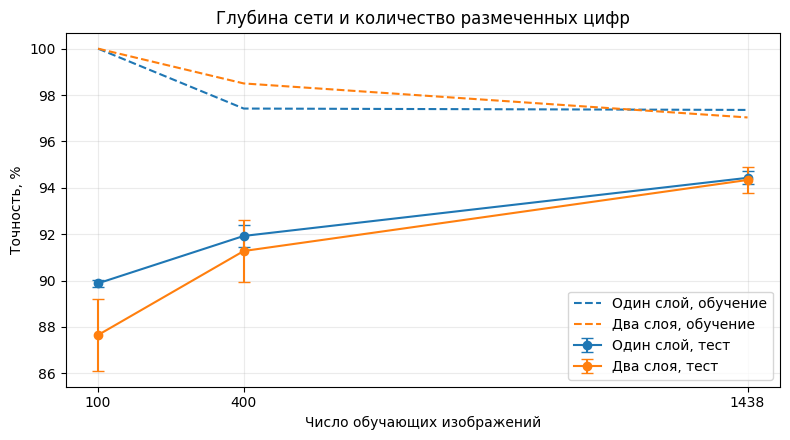

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, color in zip(architectures, ["tab:blue", "tab:orange"]):
    data = summary.xs(name, level="сеть").loc[sizes]
    ax.errorbar(sizes, data["test"], yerr=data["разброс"], marker="o",
                color=color, capsize=4, label=f"{name}, тест")
    ax.plot(sizes, data["train"], "--", color=color, label=f"{name}, обучение")
ax.set(xlabel="Число обучающих изображений", ylabel="Точность, %",
       title="Глубина сети и количество размеченных цифр", xticks=sizes)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## Вывод по измерениям
Сравниваю отдельно влияние объёма данных и распределение параметров между слоями. Для проверки устойчивости смотрю, в скольких парных запусках второй слой дал более высокую точность.

In [5]:
test_means = summary["test"].unstack("сеть")
for name in architectures:
    change = test_means.loc[sizes[-1], name] - test_means.loc[sizes[0], name]
    print(f"{name}: переход от {sizes[0]} к {sizes[-1]} изображениям "
          f"изменил среднюю тестовую точность на {change:+.2f} п.п.")
paired = results.pivot(index=["N", "seed"], columns="сеть", values="test")
for n in sizes:
    group = paired.loc[n]
    gaps = group["Два слоя"] - group["Один слой"]
    print(f"N={n}: разность (два слоя минус один) {gaps.mean():+.2f} п.п.; "
          f"два слоя выше в {(gaps > 0).sum()} из {len(gaps)} запусков, "
          f"совпадений: {(gaps == 0).sum()}.")
first = test_means.loc[sizes[0], "Два слоя"] - test_means.loc[sizes[0], "Один слой"]
last = test_means.loc[sizes[-1], "Два слоя"] - test_means.loc[sizes[-1], "Один слой"]
print(f"При переходе от малого набора к полному разность между архитектурами "
      f"изменилась на {last - first:+.2f} п.п.")

Один слой: переход от 100 к 1438 изображениям изменил среднюю тестовую точность на +4.55 п.п.
Два слоя: переход от 100 к 1438 изображениям изменил среднюю тестовую точность на +6.69 п.п.
N=100: разность (два слоя минус один) -2.23 п.п.; два слоя выше в 0 из 3 запусков, совпадений: 0.
N=400: разность (два слоя минус один) -0.65 п.п.; два слоя выше в 1 из 3 запусков, совпадений: 0.
N=1438: разность (два слоя минус один) -0.09 п.п.; два слоя выше в 1 из 3 запусков, совпадений: 1.
При переходе от малого набора к полному разность между архитектурами изменилась на +2.14 п.п.


**Ограничение.** В этом опыте я меняю распределение 2410 параметров: при добавлении слоя меняется и ширина. Результат относится к этим двум сетям, одному разбиению данных и бюджету в 400 обновлений. Разброс по трём инициализациям показывает чувствительность к стартовым весам; для оценки влияния выбора самих 100 цифр потребовались бы другие случайные подвыборки.